# Why Random Folds Fail for Overlapping Financial Labels

Each financial label uses an information interval, and the indicator records whether two labels share any time:

$$
I_i=[s_i,e_i],
\qquad
O_{ij}=\one\!\left\{I_i\cap I_j\neq\varnothing\right\}.
$$

Here, $I_i$ is the information interval for observation $i$; $s_i$ and $e_i$ are its start and end times. $O_{ij}$ is one when observations $i$ and $j$ overlap and zero otherwise; $\one\{\cdot\}$ is the indicator function.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'binance'
DATA_PATH = ensure_dataset(ROOT, 'binance_btcusdt')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
public_columns = ['Open time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Close time', 'Quote volume', 'Trades', 'Buyer base volume', 'Buyer quote volume', 'Unused']
raw = pd.read_csv(DATA_PATH, compression='zip', header=None, names=public_columns, nrows=None)
raw['time'] = pd.to_datetime(raw['Open time'], unit='ms', utc=True).dt.tz_convert(None)
raw = raw.rename(columns={'Close': 'close', 'Volume': 'volume', 'Quote volume': 'quote_volume', 'Trades': 'trades'})
raw = raw.sort_values('time').drop_duplicates('time').reset_index(drop=True)
from RiskLabAI.backtest.validation import KFold, PurgedKFold, WalkForward
FIGURES = ROOT / 'outputs' / 'figures' / '16_temporal_cross_validation'
TABLES = ROOT / 'outputs' / 'tables' / '16_temporal_cross_validation'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
minute_data = raw.set_index('time')
bars = pd.DataFrame({'Close': minute_data['close'].resample('15min').last(), 'Volume': minute_data['volume'].resample('15min').sum(), 'Quote volume': minute_data['quote_volume'].resample('15min').sum(), 'Trades': minute_data['trades'].resample('15min').sum()}).dropna()
log_close = np.log(bars['Close'])
one_bar_return = log_close.diff()
feature_frame = pd.DataFrame({'Previous return': one_bar_return.shift(1), 'One-hour return': log_close.diff(4).shift(1), 'Past volatility': one_bar_return.shift(1).rolling(16).std(), 'Log volume change': np.log1p(bars['Volume']).diff().shift(1), 'Log quote-volume change': np.log1p(bars['Quote volume']).diff().shift(1), 'Log trade-count change': np.log1p(bars['Trades']).diff().shift(1)})
label_horizon = 8
forward_return = (log_close.shift(-label_horizon) - log_close).rename('Forward return')
direction = forward_return.gt(0).where(forward_return.notna()).astype('Int64').rename('Direction')
end_time = bars.index.to_series().shift(-label_horizon).rename('End time')
public_frame = pd.concat([feature_frame, direction, forward_return, end_time], axis=1).dropna()
public_x = public_frame[feature_frame.columns].astype(float)
public_y = public_frame['Direction'].astype(int)
event_times = public_frame['End time']
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def overlap_count(train_indices, test_indices, times):
    allowed = PurgedKFold.filtered_training_indices_with_embargo(times, times.iloc[test_indices], embargo_fraction=0, continous_test_times=False)
    allowed_positions = set(times.index.get_indexer(allowed.index).tolist())
    return sum((int(int(index) not in allowed_positions) for index in train_indices))

def score_splits(name, splits):
    predictions = np.full(len(public_x), np.nan)
    records = []
    for fold, (train_indices, test_indices) in enumerate(splits, start=1):
        if len(train_indices) == 0 or public_y.iloc[train_indices].nunique() < 2:
            records.append({'Method': name, 'Fold': fold, 'Training observations': len(train_indices), 'Test observations': len(test_indices), 'Accuracy': np.nan})
            continue
        estimator = LogisticRegression(max_iter=1000, solver='lbfgs')
        estimator.fit(public_x.iloc[train_indices], public_y.iloc[train_indices])
        fold_predictions = estimator.predict(public_x.iloc[test_indices])
        predictions[test_indices] = fold_predictions
        records.append({'Method': name, 'Fold': fold, 'Training observations': len(train_indices), 'Test observations': len(test_indices), 'Accuracy': accuracy_score(public_y.iloc[test_indices], fold_predictions)})
    return (pd.DataFrame(records), predictions)

def split_matrix(split_sets, length):
    matrix = np.zeros((len(split_sets), length), dtype=int)
    for row, (train_indices, test_indices) in enumerate(split_sets):
        matrix[row, train_indices] = 1
        matrix[row, test_indices] = 2
    return matrix
split_colors = ListedColormap([palette['muted'], palette['cyan'], palette['rose'], palette['amber'], palette['violet']])
split_norm = BoundaryNorm(np.arange(-0.5, 5.5, 1), split_colors.N)
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Public Data

In [2]:
data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Market', 'Bar length', 'Label horizon', 'Analysis start', 'Analysis end', 'Observations'], 'Value': ['BTCUSDT-1m-2021-01.zip', 'Binance Data Vision', 'Bitcoin to Tether spot market', '15 minutes', '2 hours', str(public_x.index.min()), str(public_x.index.max()), f'{len(public_x):,}']})
save_table(data_provenance, 'data_provenance', 'Fixed public observations used in Chapter 14.', 'tab:chapter14-data-provenance', fit=True)
display(data_provenance)


,Field,Value
0,Archive,BTCUSDT-1m-2021-1zip
1,Provider,Binance Data Vision
2,Market,Bitcoin to Tether spot market
3,Bar length,15 minutes
4,Label horizon,2 hours
5,Analysis start,2021-01-01 04:15:00
6,Analysis end,2021-01-31 21:45:00
7,Observations,"2,951"


Cross-validation averages the held-out loss across folds, using a fit that excludes the current test fold:

$$
\widehat R_{\mathrm{CV}}
=\frac{1}{K}\sum_{k=1}^{K}
\frac{1}{|S_k|}\sum_{i\in S_k}
\ell\!\left(y_i,\widehat f^{(-k)}(x_i)\right).
$$

Here, $K$ is the number of folds; $S_k$ is test fold $k$; $|S_k|$ is its size; $x_i$ and $y_i$ are features and label. $\widehat f^{(-k)}$ is fitted without $S_k$; $\ell$ is the chosen loss; $\widehat R_{\mathrm{CV}}$ is average held-out loss.

## Fold Geometry

,Method,Training observations,Test observations,Overlapping training labels,Overlap share,Training rows not earlier than first test row
0,Random folds,2459.166667,491.833333,2327.500000,0.946459,2455.166667
1,Ordered folds,2459.166667,491.833333,13.333333,0.005422,1229.166667
2,Purged folds,2445.833333,491.833333,0,0,1222.500000


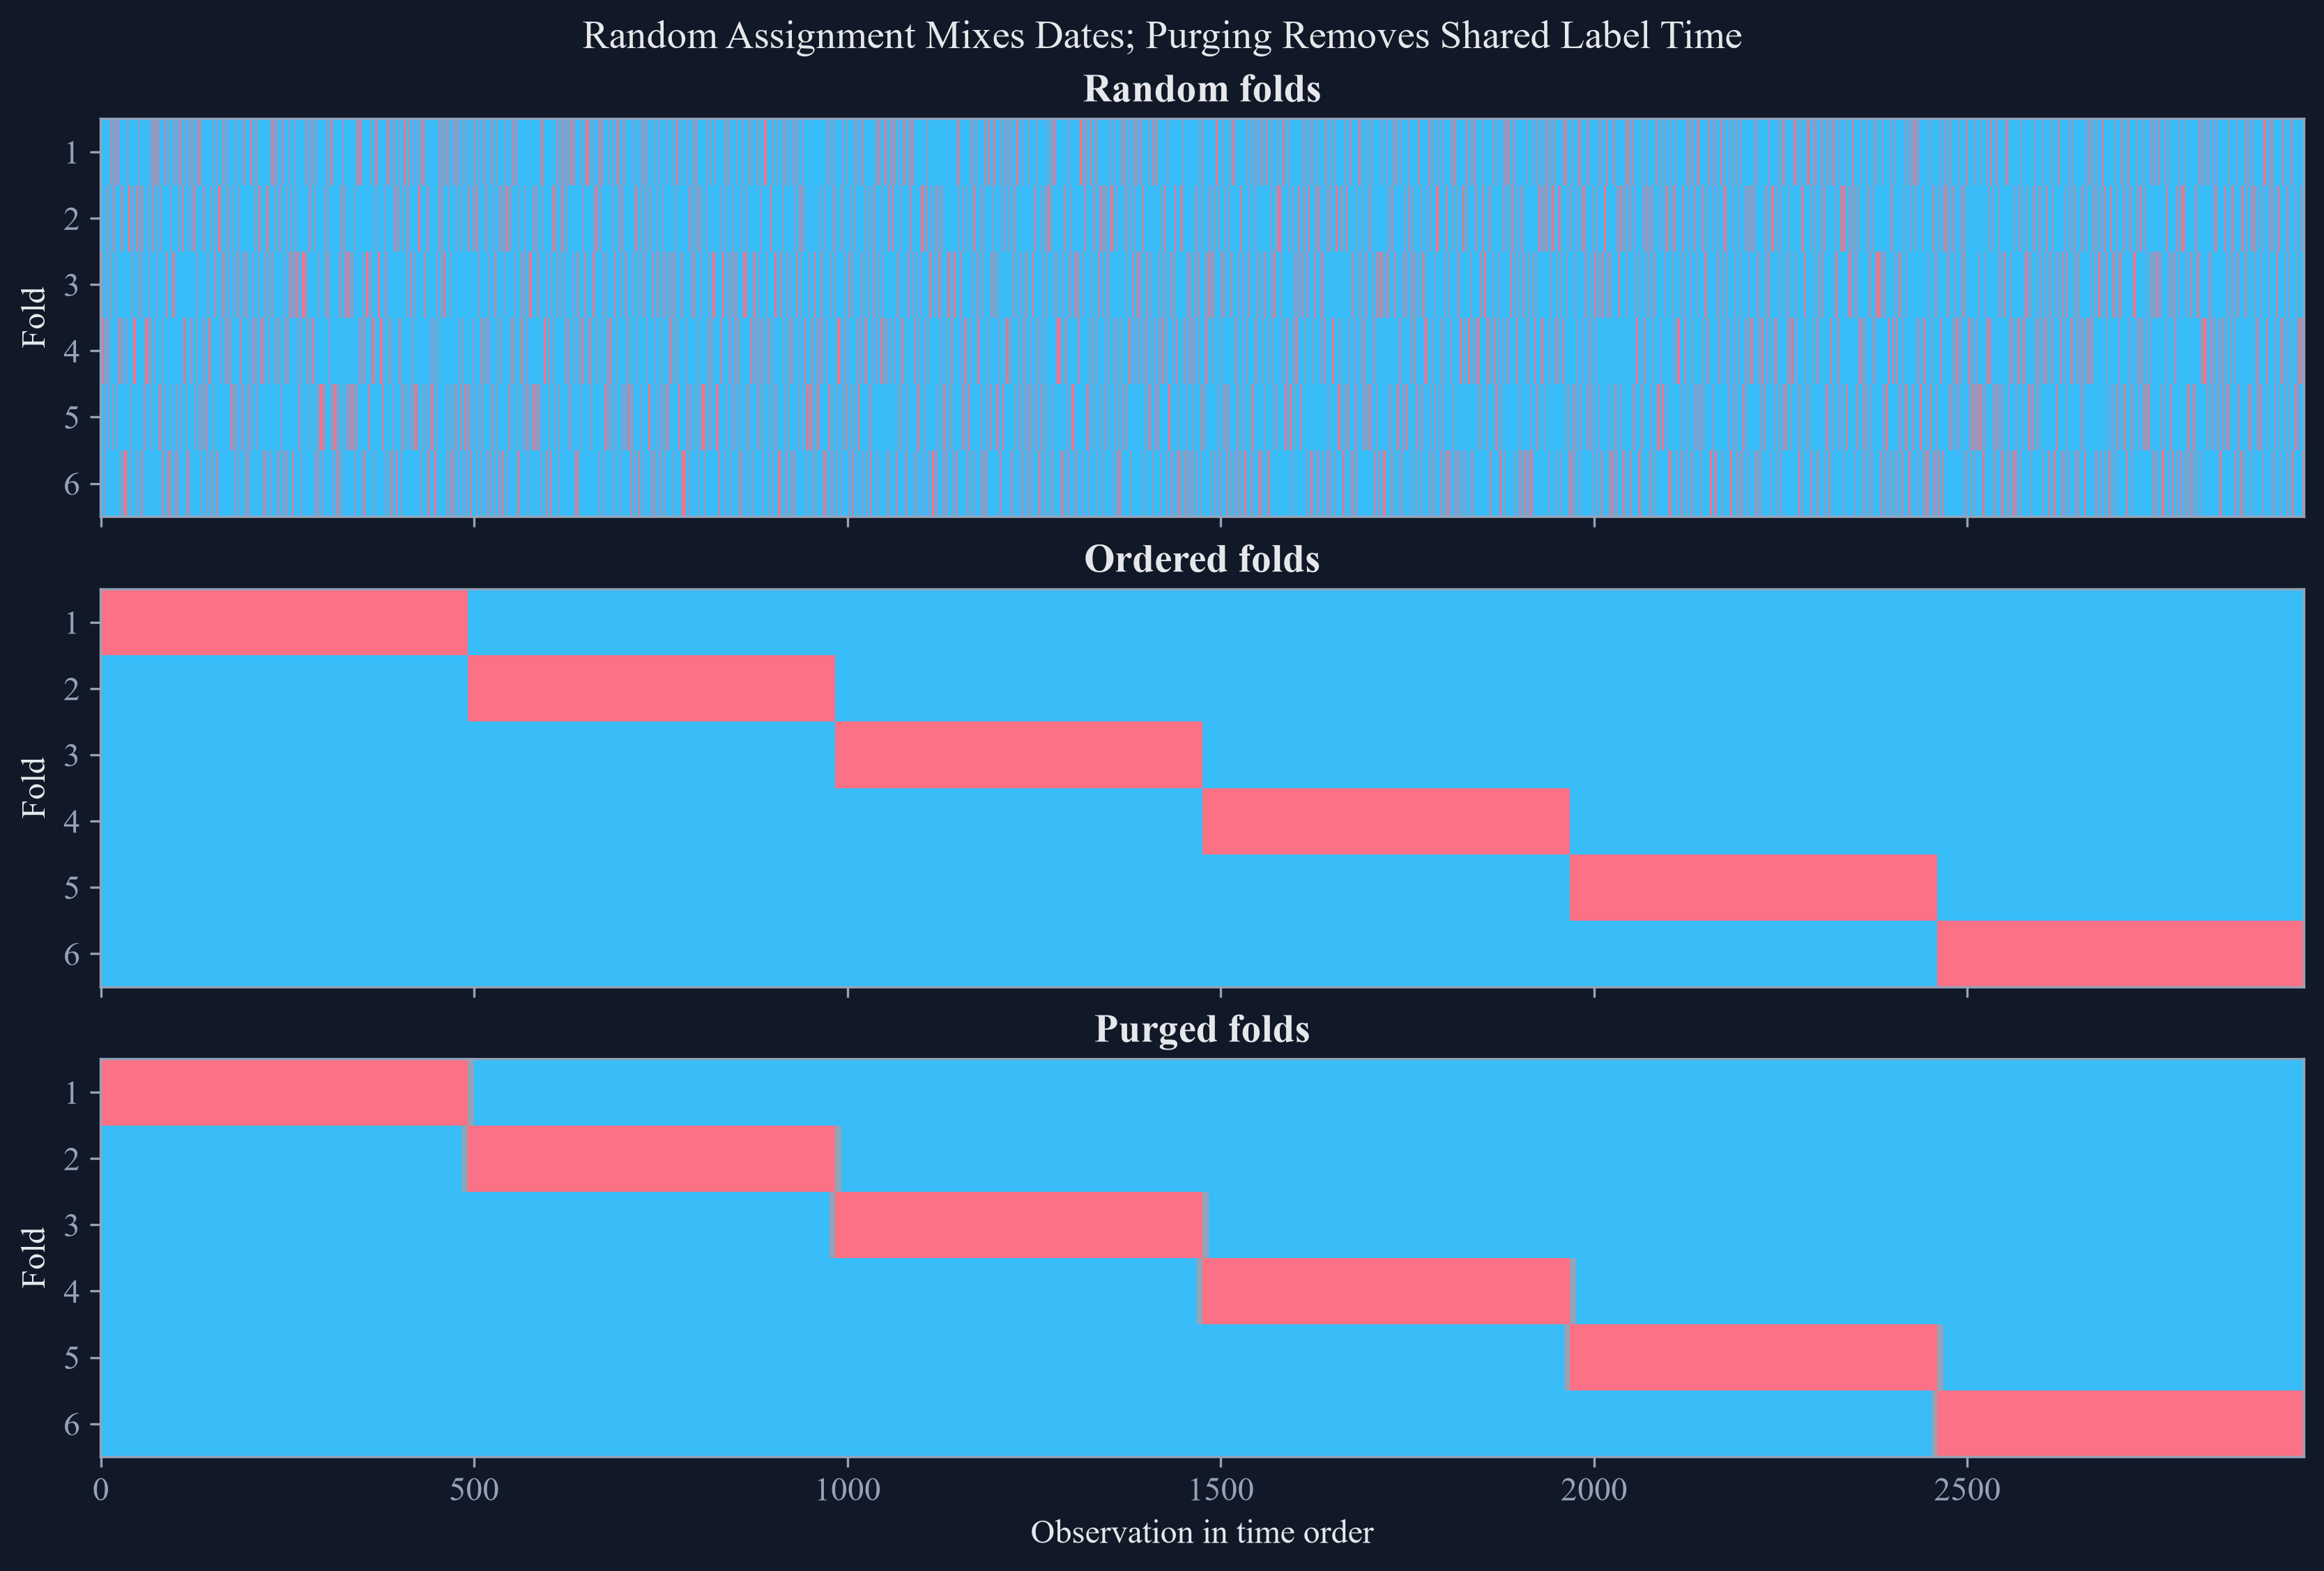

In [3]:
n_splits = 6
random_splits = list(KFold(n_splits=n_splits, shuffle=True, random_seed=14).split(public_x, public_y))
ordered_splits = list(KFold(n_splits=n_splits, shuffle=False).split(public_x, public_y))
purged_splits = list(PurgedKFold(n_splits=n_splits, times=event_times, embargo=0).split(public_x, public_y))
collections = [("Random folds", random_splits), ("Ordered folds", ordered_splits), ("Purged folds", purged_splits)]
overlap_records = []
for method, splits in collections:
    for fold, (train_indices, test_indices) in enumerate(splits, start=1):
        overlap = overlap_count(train_indices, test_indices, event_times)
        overlap_records.append({
            "Method": method,
            "Fold": fold,
            "Training observations": len(train_indices),
            "Test observations": len(test_indices),
            "Overlapping training labels": overlap,
            "Overlap share": overlap / len(train_indices),
            "Training rows not earlier than first test row": int(np.sum(train_indices >= test_indices.min())),
        })
overlap_audit = pd.DataFrame(overlap_records)
overlap_summary = overlap_audit.groupby("Method", sort=False).agg({
    "Training observations": "mean",
    "Test observations": "mean",
    "Overlapping training labels": "mean",
    "Overlap share": "mean",
    "Training rows not earlier than first test row": "mean",
}).reset_index()
save_table(overlap_summary, "fold_overlap_summary", "Information overlap and time order across six public-data folds.", "tab:chapter14-fold-overlap-summary", fit=True)
display(overlap_summary.round(6))

matrices = [split_matrix(splits, len(public_x)) for _, splits in collections]
figure, axes = plt.subplots(3, 1, figsize=(11.0, 7.4), sharex=True, constrained_layout=True)
for axis, (method, _), matrix in zip(axes, collections, matrices):
    axis.imshow(matrix, aspect="auto", interpolation="nearest", cmap=split_colors, norm=split_norm)
    axis.set_title(method)
    axis.set_ylabel("Fold")
    axis.set_yticks(np.arange(n_splits))
    axis.set_yticklabels(np.arange(1, n_splits + 1))
axes[-1].set_xlabel("Observation in time order")
figure.suptitle("Random Assignment Mixes Dates; Purging Removes Shared Label Time")
figure.savefig(FIGURES / "random_ordered_purged_geometry.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "random_ordered_purged_geometry.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "random_ordered_purged_geometry.png")))
plt.close(figure)

The leakage count measures how many training labels share information time with at least one test label in fold $k.$:

$$
L_k=\sum_{i\in T_k}
\one\!\left\{\exists j\in S_k:O_{ij}=1\right\},
\qquad
\lambda_k=\frac{L_k}{|T_k|}.
$$

Here, $T_k$ and $S_k$ are the training and test sets; $O_{ij}$ is the overlap indicator; $L_k$ is the count. $|T_k|$ is the training size; $\lambda_k$ is the overlapping share of the training set; $k$ indexes folds.

## Public Classification Results

,Method,Mean accuracy,Accuracy spread,Minimum accuracy,Maximum accuracy,Overlap share
0,Random folds,0.517107,0.015242,0.501018,0.536585,0.946459
1,Ordered folds,0.491364,0.032418,0.441057,0.524390,0.005422
2,Purged folds,0.493058,0.027545,0.457317,0.522358,0


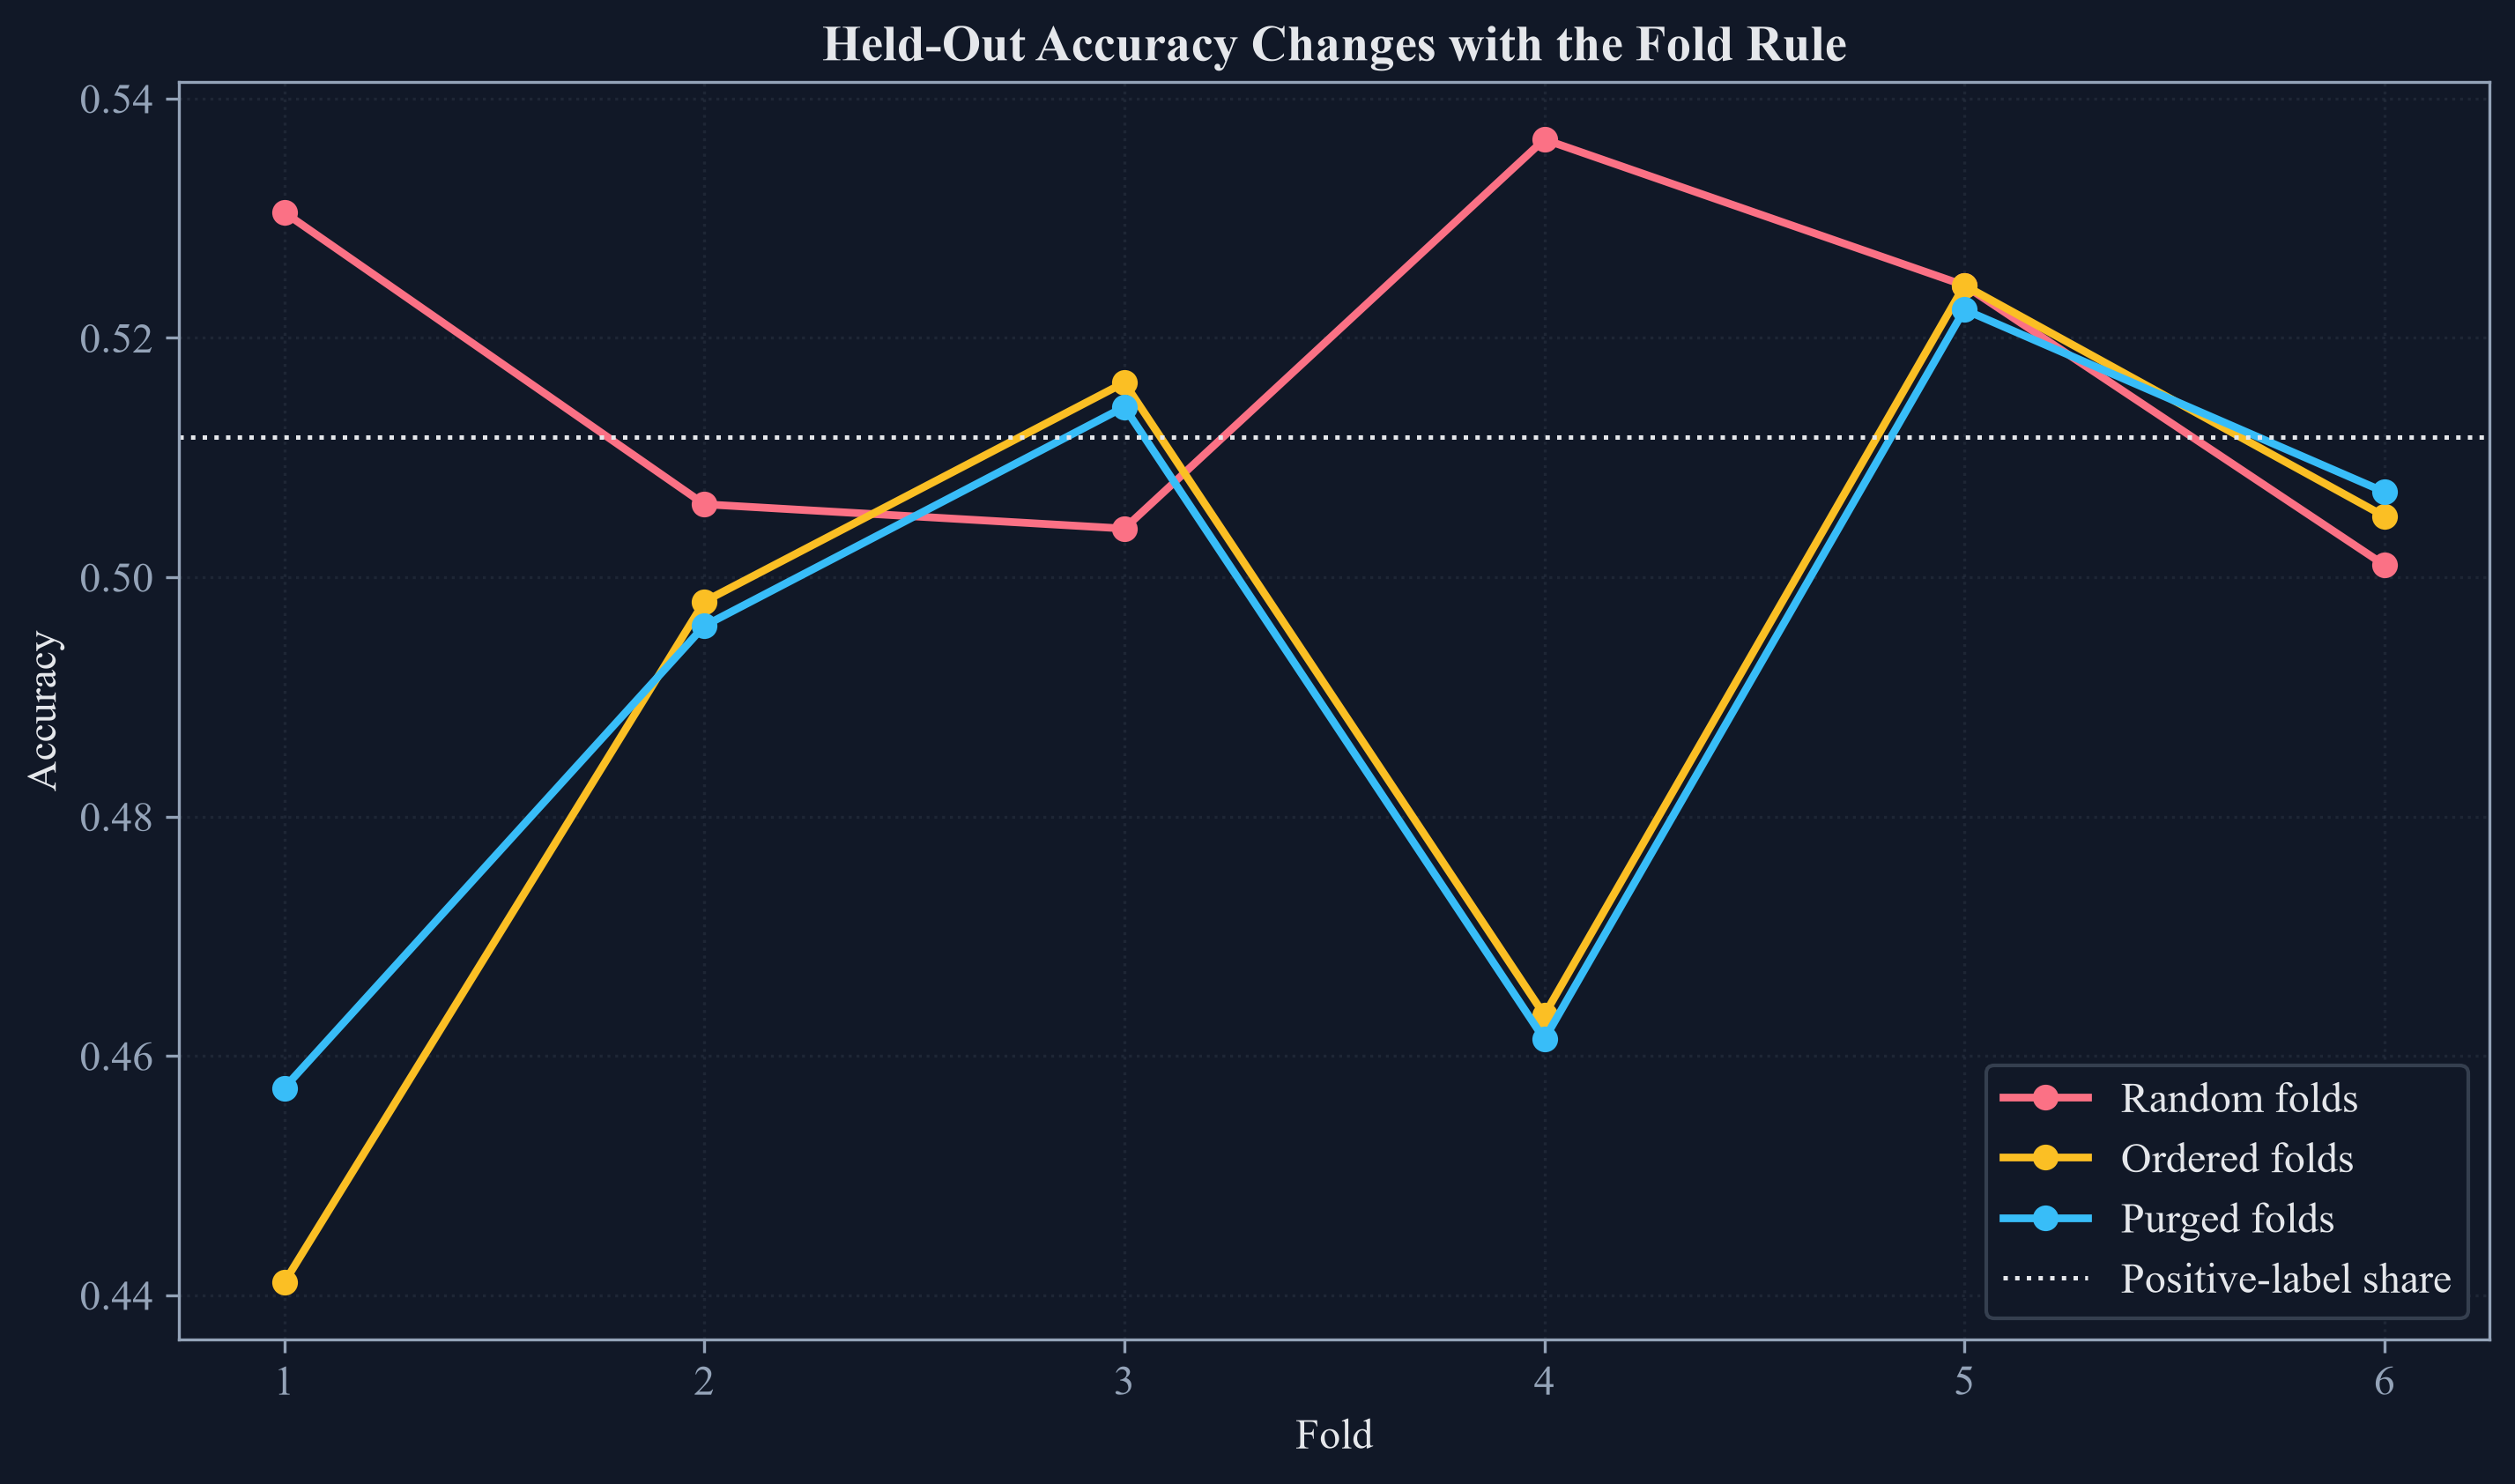

In [4]:
score_frames = []
prediction_sets = {}
for method, splits in collections:
    fold_scores, predictions = score_splits(method, splits)
    score_frames.append(fold_scores)
    prediction_sets[method] = predictions
fold_scores = pd.concat(score_frames, ignore_index=True)
score_summary = fold_scores.groupby("Method", sort=False)["Accuracy"].agg(["mean", "std", "min", "max"]).reset_index()
score_summary.columns = ["Method", "Mean accuracy", "Accuracy spread", "Minimum accuracy", "Maximum accuracy"]
score_summary = score_summary.merge(overlap_summary[["Method", "Overlap share"]], on="Method")
save_table(score_summary, "public_validation_summary", "Public classification accuracy and label overlap by validation rule.", "tab:chapter14-public-validation-summary", fit=True)
display(score_summary.round(6))

figure, axis = plt.subplots(figsize=(9.4, 5.5), constrained_layout=True)
colors = {"Random folds": palette["rose"], "Ordered folds": palette["amber"], "Purged folds": palette["cyan"]}
for method in colors:
    current = fold_scores[fold_scores["Method"] == method]
    axis.plot(current["Fold"], current["Accuracy"], marker="o", linewidth=2.1, color=colors[method], label=method)
axis.axhline(public_y.mean(), color=palette["text"], linestyle=":", linewidth=1.2, label="Positive-label share")
axis.set_title("Held-Out Accuracy Changes with the Fold Rule")
axis.set_xlabel("Fold")
axis.set_ylabel("Accuracy")
axis.set_xticks(np.arange(1, n_splits + 1))
axis.grid(alpha=0.35)
axis.legend()
figure.savefig(FIGURES / "public_fold_accuracy.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_fold_accuracy.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_fold_accuracy.png")))
plt.close(figure)

## Tests

In [5]:
assert len(public_x) > 2900
assert public_x.index.equals(public_y.index)
assert public_x.index.equals(event_times.index)
assert len(random_splits) == n_splits
assert len(ordered_splits) == n_splits
assert len(purged_splits) == n_splits
assert overlap_audit.shape == (18, 7)
assert overlap_summary.loc[overlap_summary['Method'] == 'Random folds', 'Overlap share'].iloc[0] > 0.9
assert overlap_summary.loc[overlap_summary['Method'] == 'Ordered folds', 'Overlap share'].iloc[0] > 0
assert overlap_summary.loc[overlap_summary['Method'] == 'Purged folds', 'Overlap share'].iloc[0] == 0
assert fold_scores.shape == (18, 5)
assert fold_scores['Accuracy'].between(0, 1).all()
assert np.concatenate([test for _, test in ordered_splits]).tolist() == list(range(len(public_x)))
assert (FIGURES / 'random_ordered_purged_geometry.pdf').is_file()
assert (FIGURES / 'public_fold_accuracy.pdf').is_file()
assert (TABLES / 'data_provenance.tex').is_file()
assert (TABLES / 'fold_overlap_summary.tex').is_file()
assert (TABLES / 'public_validation_summary.tex').is_file()
